# 11 · Real crack: how VisionCrack measures it

The paper tests VisionCrack on printed targets of known width (Table 1). This notebook and notebook 12 add a **check on a real crack**:
does the same code work on a crack in a wall, and how large is the error against a manual reading?

* **Crack and label.** The VisionCrack label, printed on clear film, lies over a crack in a painted wall. The app auto-captured photos
  of it; the 10 used here are in `data/raw/images/` (notebook 10 shows how they were picked from 20).
* **Measuring point.** One spot per crack, as an inspector reads it: the 2-mm part of the crack 7–9 mm from the label frame
  (≈ 34 pixel rows, one row = one pixel), where the crack-width ruler was read.
* **GT.** 0.45 mm, crack-width ruler reading by the author.
* **Five options** turn the rows of the measuring point into one width:

| Option | Width of one row | One number from the rows | Scale |
|---|---|---|---|
| **middle row** | sub-pixel, edges at half height between wall and crack | the single row in the middle (one line, like reading one spot) | barcode |
| **median** | same | median of the rows | barcode |
| **mean** | same | mean of the rows | barcode |
| **Table 1 rule, > 2 px** | dark run below the barcode's Otsu threshold (paper Sec. 2.3), runs > 2 px | mean after dropping rows outside mean ± 1.645 σ | 50 mm / label width |
| **Table 1 rule, > 6 px** | same, runs > 6 px (paper's filter) | same | same |

| | |
|---|---|
| **Inputs** | `data/raw/images/VisionCrack_*.JPG` (10 photos) |
| **Outputs** | `results/tables/field_capture_checks.csv`, `field_rows_photo1.csv`, `field_widths.csv`; `results/figures/field_how_measured.png` |
| **Runtime** | ~15 s |

In [ ]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import visioncrack as vc
from visioncrack import io, field
from visioncrack.constants import CLIP_Z, LABEL_WIDTH_MM, ROTATION_MAX_DEG
from visioncrack.metrics import half_up
from visioncrack.width import binarize, blur_gray
pd.set_option('display.width', 200)
print('visioncrack', vc.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
FIG = io.results_dir('figures'); TAB = io.results_dir('tables')

files = sorted((io.data_dir() / 'images').glob('VisionCrack_*.JPG'))
assert len(files) == 10, f'expected 10 photos, found {len(files)}'
NAMES = [f'VisionCrack {i + 1}' for i in range(len(files))]

POINT_MM = (7.0, 9.0)      # measuring point: the 2-mm part of the crack 7–9 mm from the label frame, where the ruler was read
GT_MM = 0.45               # crack-width ruler reading by the author at the measuring point

# five ways to get one width for the measuring point (name: arguments of field.point_values)
OPTIONS = {
    'middle row':           dict(rule='subpixel', scale='barcode', stat='middle'),
    'median':               dict(rule='subpixel', scale='barcode', stat='median'),
    'mean':                 dict(rule='subpixel', scale='barcode', stat='mean'),
    'Table 1 rule, > 2 px': dict(rule='paper', scale='label', stat='clipped', min_run=2),
    'Table 1 rule, > 6 px': dict(rule='paper', scale='label', stat='clipped', min_run=6),
}
rs = [field.measure_field(f) for f in files]
V = pd.DataFrame({name: [field.point_values(r, points=(POINT_MM,), **kw)[0] for r in rs] for name, kw in OPTIONS.items()},
                 index=NAMES)
print(len(rs), 'photos measured; empty values:', int(V.isna().sum().sum()))

visioncrack 0.1.0 | numpy 2.2.6 | pandas 2.3.0


10 photos measured; empty values: 0


## 1 · Capture checks

Every photo must pass the paper's capture gates: label found, barcode decoded, in-plane angle below 2°.

In [ ]:
chk = pd.DataFrame([{
    'file': r.file, 'barcode': r.code, 'angle_deg': r.angle_deg,
    'keystone_pct': 100 * max(abs(r.tb_ratio - 1), abs(r.lr_ratio - 1)),
    'scale_barcode_mm_px': r.scale, 'scale_label_mm_px': LABEL_WIDTH_MM / r.frame_w_px,
} for r in rs], index=NAMES)
assert (chk.angle_deg.abs() < ROTATION_MAX_DEG).all() and (chk.barcode == '3lAy').all()
chk.to_csv(TAB / 'field_capture_checks.csv', float_format='%.5f')
print('✓ all 10 photos pass the capture gates')
chk.round(4)

✓ all 10 photos pass the capture gates


,file,barcode,angle_deg,keystone_pct,scale_barcode_mm_px,scale_label_mm_px
VisionCrack 1,VisionCrack_1793160054973.JPG,3lAy,0.1805,0.6084,0.0587,0.0585
VisionCrack 2,VisionCrack_1793160064902.JPG,3lAy,-0.2768,0.9346,0.0578,0.0576
VisionCrack 3,VisionCrack_1793160076169.JPG,3lAy,-0.1063,0.4042,0.0589,0.0589
VisionCrack 4,VisionCrack_1793160083161.JPG,3lAy,0.0000,0.7889,0.0579,0.0579
VisionCrack 5,VisionCrack_1793160100977.JPG,3lAy,-0.1473,0.7720,0.0571,0.0569
VisionCrack 6,VisionCrack_1793160127492.JPG,3lAy,0.0000,0.6963,0.0573,0.0573
VisionCrack 7,VisionCrack_1793160143727.JPG,3lAy,0.4968,1.0594,0.0583,0.0580
VisionCrack 8,VisionCrack_1793160163233.JPG,3lAy,0.0000,0.9877,0.0579,0.0575
VisionCrack 9,VisionCrack_1793160168114.JPG,3lAy,0.3581,0.9247,0.0573,0.0570
VisionCrack 10,VisionCrack_1793160181953.JPG,3lAy,0.3515,0.6067,0.0591,0.0590


## 2 · The steps on photo 1

1. **Label straight.** The photo is rotated so the label is level. The measuring point is the 2-mm band 7–9 mm from the top of the red frame.
2. **Scale.** From the 18 barcode bars of known width (*barcode*), or 50 mm ÷ label width in pixels (*label*, as in the paper).
3. **One row, two ways** (panel ③):
   * **half height**: the edges are where the grey curve crosses half-way between wall and crack centre (sub-pixel);
   * **Table 1 rule**: pixels darker than the barcode's Otsu threshold form a dark run; its length is the width in whole pixels.
4. **One number** per option, as in the table above.

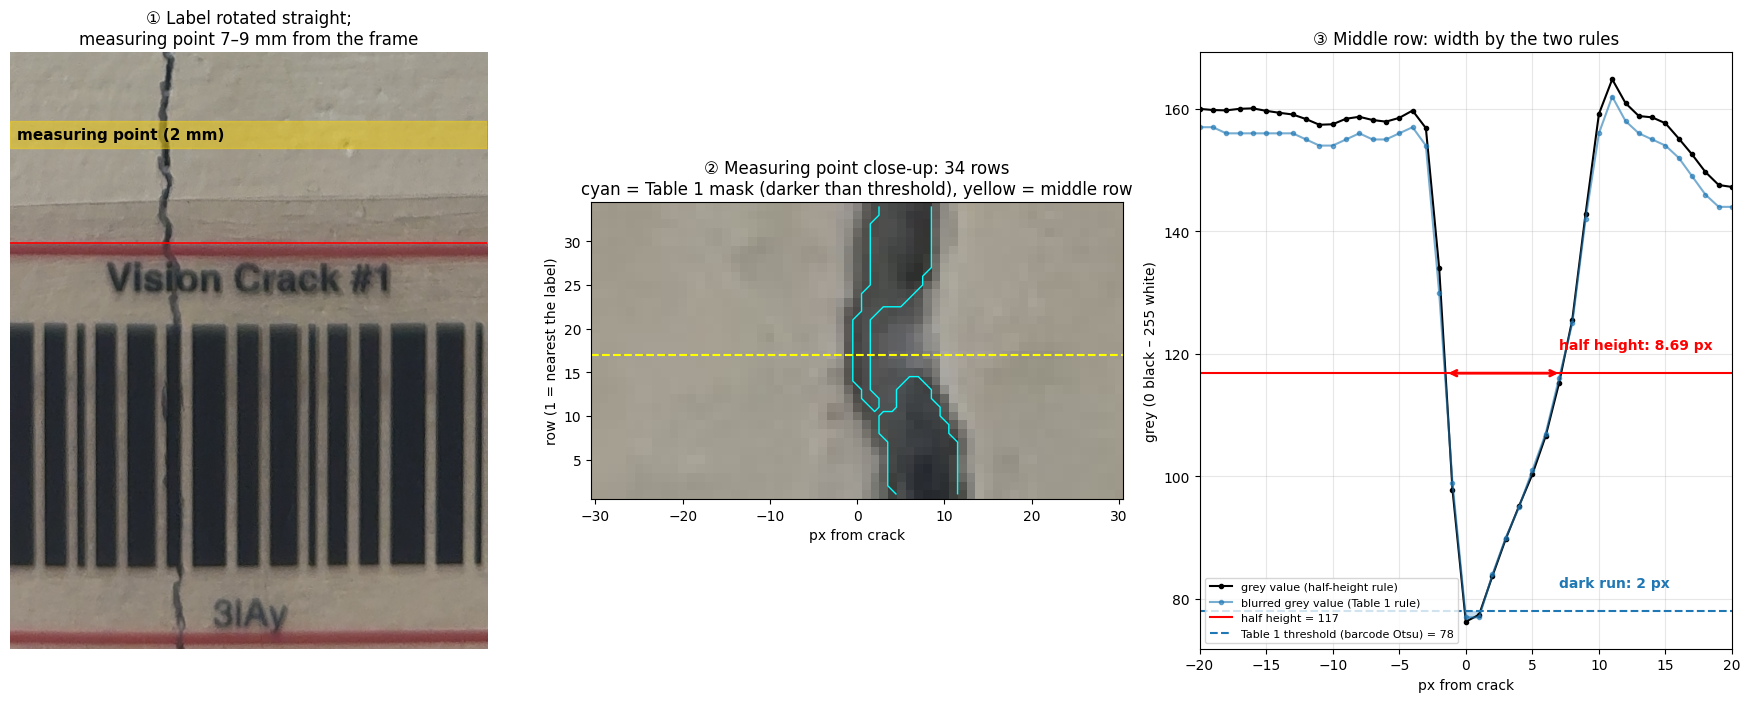

In [ ]:
k1 = 0
r, img = rs[k1], vc.read_rgb(files[k1])
(cx, cy), (w, h), _ = field.find_red_label(img); W, H = max(w, h), min(w, h)
rot = field.derotate(img, r.angle_deg, (cx, cy)); g = field.grey(rot); top = int(cy - H / 2)
y0, y1 = int(top - field.BAND_MM[1] / r.scale), int(top - field.BAND_MM[0] / r.scale)
_, xs = field.crack_widths(g, int(cx - W / 2), int(cx + W / 2), y0, y1)
bb = (int(cx - W / 2 + .04 * W), int(cy - H / 2 + .35 * H), int(cx + W / 2 - .04 * W), int(cy - H / 2 + .75 * H))
t, _ = binarize(blur_gray(rot[bb[1]:bb[3], bb[0]:bb[2]]))
s_lab = LABEL_WIDTH_MM / r.frame_w_px

lo, hi = POINT_MM
idx = np.where((r.rows_y_mm >= lo) & (r.rows_y_mm < hi))[0]
idx = idx[np.argsort(r.rows_y_mm[idx])]            # row 1 = nearest the label
mid = (len(idx) - 1) // 2 + 1                      # middle row, counted from the label
k = idx[mid - 1]; yrow, xrow = y0 + k, int(xs[k])
run_px = r.rows_px_paper_all[k]

fig = plt.figure(figsize=(18, 7))
a1 = fig.add_subplot(1, 3, 1)
X0, X1, Y0, Y1 = int(cx - 0.35 * W), int(cx + 0.35 * W), int(top - 14 / r.scale), int(cy + 0.5 * H)
a1.imshow(rot[Y0:Y1, X0:X1])
a, b = top - hi / r.scale - Y0, top - lo / r.scale - Y0
a1.axhspan(a, b, color='#ffd700', alpha=.45)
a1.text(8, (a + b) / 2, 'measuring point (2 mm)', va='center', fontsize=11, fontweight='bold')
a1.axhline(top - Y0, color='red', lw=1.2)
a1.set_title('① Label rotated straight;\nmeasuring point 7–9 mm from the frame'); a1.axis('off')

a2 = fig.add_subplot(1, 3, 2)
ylo, yhi = y0 + idx.min(), y0 + idx.max() + 1
crop = rot[ylo - 2:yhi + 2, xrow - 30:xrow + 31]
dark = blur_gray(crop)[2:-2] <= t
a2.imshow(crop[2:-2][::-1], interpolation='nearest', extent=(-30.5, 30.5, 0.5, len(idx) + 0.5), origin='lower')
a2.contour(np.arange(-30, 31), np.arange(1, len(idx) + 1), dark[::-1].astype(float), levels=[.5], colors='cyan', linewidths=1)
a2.axhline(mid, color='yellow', lw=1.5, ls='--')
a2.set_title(f'② Measuring point close-up: {len(idx)} rows\ncyan = Table 1 mask (darker than threshold), yellow = middle row')
a2.set_xlabel('px from crack'); a2.set_ylabel('row (1 = nearest the label)')

a3 = fig.add_subplot(1, 3, 3)
xx = np.arange(-45, 46)
prof = g[yrow, xrow - 45:xrow + 46].astype(float)
i0 = int(np.argmin(prof)); wall, core = float(np.median(prof)), float(prof[i0]); half = (wall + core) / 2
L, R = [ab for ab in field.half_max_runs(prof, wall, core) if ab[0] <= i0 <= ab[1] + 1][0]
strip = blur_gray(rot[yrow - 2:yrow + 3, xrow - 45:xrow + 46])[2].astype(float)
a3.plot(xx, prof, 'k.-', label='grey value (half-height rule)')
a3.plot(xx, strip, '.-', color='tab:blue', alpha=.6, label='blurred grey value (Table 1 rule)')
a3.axhline(half, color='red', label=f'half height = {half:.0f}')
a3.axhline(t, color='tab:blue', ls='--', label=f'Table 1 threshold (barcode Otsu) = {t:.0f}')
a3.annotate('', xy=(L - 45, half), xytext=(R - 45, half), arrowprops=dict(arrowstyle='<->', color='red', lw=2))
a3.fill_between(xx, strip, t, where=strip <= t, color='tab:blue', alpha=.25)
a3.text(7, half + 4, f'half height: {R - L:.2f} px', color='red', fontweight='bold')
a3.text(7, t + 4, f'dark run: {run_px:.0f} px', color='tab:blue', fontweight='bold')
a3.set_xlim(-20, 20); a3.set_xlabel('px from crack'); a3.set_ylabel('grey (0 black – 255 white)'); a3.grid(alpha=.3)
a3.set_title('③ Middle row: width by the two rules'); a3.legend(fontsize=8, loc='lower left')
plt.tight_layout(); plt.savefig(FIG / 'field_how_measured.png', dpi=200); plt.show()

**Table M1 · Photo 1: every row of the measuring point**, with the five options at the bottom.

In [ ]:
sub_px = r.rows_mm[idx] / r.scale
runs = r.rows_px_paper_all[idx]
def used(mr):
    v = runs > mr
    m, s = runs[v].mean(), runs[v].std()
    return np.select([v & (runs >= m - CLIP_Z * s) & (runs <= m + CLIP_Z * s), v], ['yes', 'no (outlier)'], f'no (≤ {mr} px)')
m1 = pd.DataFrame({'row (1 = nearest label)': np.arange(1, len(idx) + 1).astype(str).astype(object),
                   'half height (px)': sub_px.round(2), 'half height (mm)': (sub_px * r.scale).round(4),
                   'dark run (px)': runs, 'used, > 2 px': used(2), 'used, > 6 px': used(6)})
m1.loc[mid - 1, 'row (1 = nearest label)'] = f'{mid} ← middle row'
m1.to_csv(TAB / 'field_rows_photo1.csv', index=False)
display(m1)
V.iloc[[k1]].T.rename(columns={NAMES[k1]: 'photo 1, width (mm)'}).round(4)

,row (1 = nearest label),half height (px),half height (mm),dark run (px),"used, > 2 px","used, > 6 px"
0,1,9.00,0.5281,7.0,yes,yes
1,2,9.06,0.5315,8.0,yes,yes
2,3,8.84,0.5188,8.0,yes,yes
3,4,8.53,0.5002,8.0,yes,yes
4,5,8.67,0.5087,8.0,yes,yes
5,6,9.30,0.5457,8.0,yes,yes
6,7,10.06,0.5899,8.0,yes,yes
7,8,10.41,0.6108,8.0,yes,yes
8,9,10.46,0.6138,8.0,yes,yes
9,10,10.56,0.6193,7.0,yes,yes


,"photo 1, width (mm)"
middle row,0.5091
median,0.5298
mean,0.5458
"Table 1 rule, > 2 px",0.4070
"Table 1 rule, > 6 px",0.4388


## 3 · Width at the measuring point, all 10 photos and five options (mm)

In [ ]:
V.to_csv(TAB / 'field_widths.csv', float_format='%.5f')
V.round(4)

,middle row,median,mean,"Table 1 rule, > 2 px","Table 1 rule, > 6 px"
VisionCrack 1,0.5091,0.5298,0.5458,0.4070,0.4388
VisionCrack 2,0.4666,0.5224,0.5455,0.4002,0.4276
VisionCrack 3,0.5374,0.5241,0.5474,0.4041,0.4294
VisionCrack 4,0.4876,0.5166,0.5381,0.4001,0.4360
VisionCrack 5,0.4738,0.5195,0.5416,0.3659,0.4393
VisionCrack 6,0.4712,0.5230,0.5392,0.3826,0.4296
VisionCrack 7,0.5082,0.5257,0.5462,0.3649,0.4060
VisionCrack 8,0.4897,0.5245,0.5448,0.3118,0.4185
VisionCrack 9,0.5000,0.5198,0.5394,0.3439,0.3987
VisionCrack 10,0.5721,0.5248,0.5490,0.3720,0.4131


### Notes
* **Table 1 rule, > 2 px vs > 6 px.** The paper's 6-px filter (≈ 0.35 mm here) was set for printed bars of 0.55 mm and wider. A 0.45 mm crack
  is ≈ 7–8 px wide and narrows to 3–6 px in places, so the 6-px filter keeps only the wider rows. 2 px (≈ 0.12 mm) only removes noise.
  On the printed targets both give the same Table 1 (every bar is ≥ 9 px wide; checked in notebook 12).
* **Threshold.** The Otsu threshold comes from the black barcode, as in the paper. A real crack is grey, so this threshold sits below
  the crack's half height and the Table 1 rule sees a narrower crack than the half-height rule (panel ③).
* **Middle row** depends on exactly where the 2-mm band starts: one row up or down gives a neighbouring width.